In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 学号
STUDENT_ID = 20244080232
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] python_hw
[学号] 20244080232
[机器指纹] 98e142a17f2aaab1
[RUN_ID] 20244080232-98e142a17f2aaab1


In [2]:
# ==========实验1：NumPy数组、数据类型与索引==========
import numpy as np

# 任务1：分别创建整数、浮点数和布尔值 ndarray，输出dtype、shape、ndim
arr_int = np.array([10, 20, 30, 40], dtype=int)
arr_float = np.array([1.1, 2.2, 3.3, 4.4], dtype=float)
arr_bool = np.array([True, False, True, False], dtype=bool)

print("=====任务1=====")
print("整数数组：")
print(arr_int)
print(f"dtype:{arr_int.dtype}, shape:{arr_int.shape}, ndim:{arr_int.ndim}\n")

print("浮点数数组：")
print(arr_float)
print(f"dtype:{arr_float.dtype}, shape:{arr_float.shape}, ndim:{arr_float.ndim}\n")

print("布尔数组：")
print(arr_bool)
print(f"dtype:{arr_bool.dtype}, shape:{arr_bool.shape}, ndim:{arr_bool.ndim}\n")

# 任务2：np.arange(12)改变形状
print("=====任务2=====")
a = np.arange(12)
print("原始一维数组：")
print(a)
a_34 = a.reshape(3, 4)
print("\nreshape(3,4):")
print(a_34)
a_232 = a.reshape(2, 3, 2)
print("\nreshape(2,3,2):")
print(a_232)

# 任务3：(3,4)数组索引操作
print("\n=====任务3=====")
print("(3,4)数组：")
print(a_34)
row2 = a_34[1, :]        # 取第2行（下标从0开始）
col1_3 = a_34[:, 0:3]    # 取第1至第3列
over6 = a_34[a_34 > 6]   # 大于6的元素
print(f"\n取第2行：{row2}, shape={row2.shape}")
print(f"取第1~3列：\n{col1_3}, shape={col1_3.shape}")
print(f"大于6的元素：{over6}, shape={over6.shape}")

# 任务4：逻辑条件筛选
print("\n=====任务4=====")
b = np.arange(10)
print("原始数组b：", b)
res_or = b[(b < 2) | (b > 7)]      # 小于2 或 大于7
res_and = b[(b > 3) & (b < 7)]     # 大于3 且 小于7
print("小于2或大于7：", res_or)
print("大于3且小于7：", res_and)

# 任务5：逐元素乘法、矩阵乘法对比
print("\n=====任务5=====")
m1 = np.array([[1, 2], [3, 4]])
m2 = np.array([[5, 6], [7, 8]])
print("m1：")
print(m1)
print("m2：")
print(m2)

ele1 = m1 * m2
ele2 = np.multiply(m1, m2)
mat1 = m1 @ m2
mat2 = np.matmul(m1, m2)

print("\n逐元素乘法 *：")
print(ele1)
print("np.multiply()：")
print(ele2)

print("\n矩阵乘法 @：")
print(mat1)
print("np.matmul()：")
print(mat2)


=====任务1=====
整数数组：
[10 20 30 40]
dtype:int64, shape:(4,), ndim:1

浮点数数组：
[1.1 2.2 3.3 4.4]
dtype:float64, shape:(4,), ndim:1

布尔数组：
[ True False  True False]
dtype:bool, shape:(4,), ndim:1

=====任务2=====
原始一维数组：
[ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3,4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

=====任务3=====
(3,4)数组：
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

取第2行：[4 5 6 7], shape=(4,)
取第1~3列：
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]], shape=(3, 3)
大于6的元素：[ 7  8  9 10 11], shape=(5,)

=====任务4=====
原始数组b： [0 1 2 3 4 5 6 7 8 9]
小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]

=====任务5=====
m1：
[[1 2]
 [3 4]]
m2：
[[5 6]
 [7 8]]

逐元素乘法 *：
[[ 5 12]
 [21 32]]
np.multiply()：
[[ 5 12]
 [21 32]]

矩阵乘法 @：
[[19 22]
 [43 50]]
np.matmul()：
[[19 22]
 [43 50]]


### 任务1 说明
Python列表：元素可以是不同类型，保存对象引用，没有统一dtype。
NumPy ndarray：全部元素必须为同一数据类型，内存连续存储，拥有shape、ndim属性，支持向量化快速运算。

### 任务2 说明
reshape改变数组形状时，**新数组各维度乘积必须等于原数组元素总个数**。
np.arange(12)共12个元素：3×4=12，2×3×2=12，满足条件。

### 任务3 说明
numpy下标从0开始；题目第2行对应下标1，第1‑3列对应列下标0,1,2。

### 任务5 说明
1. `*`、`np.multiply()`：**逐元素乘法**，对应位置元素直接相乘，要求两个数组shape完全相同。
2. `@`、`np.matmul()`：**矩阵乘法**，遵循数学矩阵运算规则，左矩阵列数等于右矩阵行数。


In [3]:
# ==========实验2：随机抽样、统计与缺失值==========
import numpy as np
np.random.seed(666)

# 任务1：生成1000个均值70，标准差10模拟成绩，限制0~100
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
print("====任务1 模拟成绩统计====")
print(f"样本数：{scores.size}")
print(f"最小值：{scores.min():.2f}")
print(f"最大值：{scores.max():.2f}")
print(f"均值：{scores.mean():.2f}")
print(f"标准差：{scores.std():.2f}")
print(f"极差：{scores.max()-scores.min():.2f}")

# 任务2：从np.arange(1,11)不放回抽5个，均匀抽样 vs 加权抽样
pop = np.arange(1,11)
# 均匀不放回抽样
sample_uniform = np.random.choice(pop, size=5, replace=False)
# 按整数大小比例加权抽样
p_weight = pop / pop.sum()
sample_weighted = np.random.choice(pop, size=5, replace=False, p=p_weight)
print("\n====任务2 抽样====")
print(f"总体数组pop：{pop}")
print(f"均匀不放回抽样结果：{sample_uniform}")
print(f"加权不放回抽样结果：{sample_weighted}")

# 任务3：permutation（不改动原数组） vs shuffle（原地打乱）
arr_ori = np.array([1,2,3,4,5])
arr_perm = np.random.permutation(arr_ori)
print("\n====任务3 随机排列对比====")
print(f"permutation操作前原数组：{arr_ori}")
print(f"permutation返回新数组：{arr_perm}")
print(f"permutation操作后原数组：{arr_ori}")

arr_shuf = np.array([1,2,3,4,5])
np.random.shuffle(arr_shuf)
print(f"shuffle操作之后数组：{arr_shuf}")

# 任务4：第10、20、30个值设为nan，下标9,19,29
scores_nan = scores.copy()
scores_nan[[9,19,29]] = np.nan
cnt_nan = np.sum(np.isnan(scores_nan))
mean_raw = np.mean(scores_nan)
mean_ignore_nan = np.nanmean(scores_nan)
print("\n====任务4 缺失值处理====")
print(f"缺失值数量：{cnt_nan}")
print(f"普通np.mean（含nan）: {mean_raw}")
print(f"np.nanmean 忽略缺失值均值: {mean_ignore_nan:.2f}")

# 任务5：构建内存表格，不存磁盘，给实验4使用
import pandas as pd
idx_arr = np.arange(len(scores_nan))
df_score = pd.DataFrame({"index": idx_arr, "score": scores_nan})
print("\n====任务5 内存表格（前5行）====")
print(df_score.head())


====任务1 模拟成绩统计====
样本数：1000
最小值：38.04
最大值：100.00
均值：69.90
标准差：10.01
极差：61.96

====任务2 抽样====
总体数组pop：[ 1  2  3  4  5  6  7  8  9 10]
均匀不放回抽样结果：[3 7 9 2 5]
加权不放回抽样结果：[ 9 10  3  6  8]

====任务3 随机排列对比====
permutation操作前原数组：[1 2 3 4 5]
permutation返回新数组：[2 4 5 1 3]
permutation操作后原数组：[1 2 3 4 5]
shuffle操作之后数组：[1 3 4 2 5]

====任务4 缺失值处理====
缺失值数量：3
普通np.mean（含nan）: nan
np.nanmean 忽略缺失值均值: 69.90

====任务5 内存表格（前5行）====
   index      score
0      0  78.241881
1      1  74.799660
2      2  81.734680
3      3  79.090481
4      4  64.282785


### 任务1说明
`np.random.normal()`生成正态分布随机数；`np.clip()`将数值裁剪限定在`[0,100]`，避免成绩出现负数或者大于100的情况。

### 任务2说明
`np.random.choice()`实现抽样。
- 均匀抽样：每个元素被抽到的概率完全相等，不设置p参数。
- 加权抽样：通过参数`p`指定每个元素抽取概率，这里概率和元素本身大小成正比。
- `replace=False`代表**不放回抽样**，同一个元素不会被多次抽取。

### 任务3说明
- `np.random.permutation()`：生成打乱后的**新数组**，原始数组保持不变。
- `np.random.shuffle()`：**原地直接修改原数组**，无返回值。

### 任务4说明
NaN代表缺失值。普通`np.mean()`只要数组存在NaN，计算结果直接返回NaN；`np.nanmean()`会自动跳过所有NaN，只用有效数字计算均值。
题目要求修改第10、20、30个元素，numpy下标从0开始，对应下标9,19,29。

### 任务5说明
使用Pandas在内存中创建DataFrame表格，仅保存在内存，**不写入本地文件**，后续实验4可以直接使用`df_score`这个变量。


====任务1 解线性方程组====
方程组解 x=2.00, y=3.00
代入验证 A@sol = [9. 8.]，应等于[9 8]

====任务2 方程求根 x^2-2=0====
正根求解成功：True, 根=1.4142, f(x)=8.8818e-16
负根求解成功：True, 根=-1.4142, f(x)=8.8818e-16

====任务3 函数极小值====
极小点x=-0.5000, 函数最小值=1.7500
解析解极小点 x = -0.5，最小值 = 1.7500

====任务4 独立样本t检验====
t统计量 = -7.3980, p值 = 0.0000
p < 0.05，拒绝原假设，两组均值存在显著差异


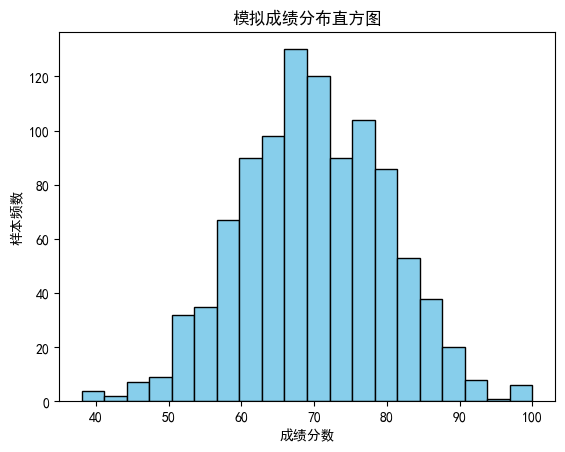

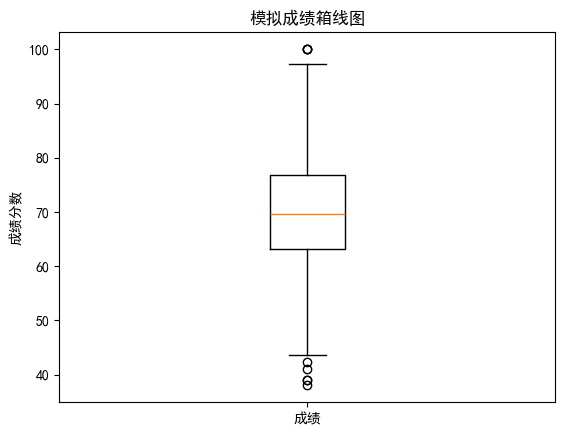

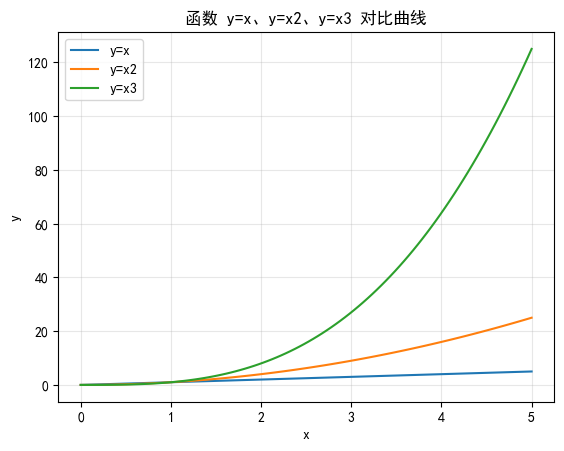

In [4]:
# ==========实验3：SciPy数值计算与Matplotlib可视化==========
import numpy as np
import scipy.linalg
import scipy.optimize
import scipy.stats
import matplotlib.pyplot as plt

np.random.seed(666)

# 任务1：解线性方程组 3x+y=9； x+2y=8
print("====任务1 解线性方程组====")
A = np.array([[3, 1],
              [1, 2]])
b = np.array([9, 8])
sol = scipy.linalg.solve(A, b)
print(f"方程组解 x={sol[0]:.2f}, y={sol[1]:.2f}")
# 代入验证
verify = A @ sol
print(f"代入验证 A@sol = {verify}，应等于{b}")

# 任务2：求 x²−2 =0 的正根、负根
print("\n====任务2 方程求根 x^2-2=0====")
def f(x):
    return x**2 - 2

# 正根，初猜 x=2
res_pos = scipy.optimize.root(f, x0=2)
# 负根，初猜 x=-2
res_neg = scipy.optimize.root(f, x0=-2)

print(f"正根求解成功：{res_pos.success}, 根={res_pos.x[0]:.4f}, f(x)={f(res_pos.x[0]):.4e}")
print(f"负根求解成功：{res_neg.success}, 根={res_neg.x[0]:.4f}, f(x)={f(res_neg.x[0]):.4e}")

# 任务3：求 f(x)=x²+x+2 的最小值
print("\n====任务3 函数极小值====")
def fun_min(x):
    return x**2 + x + 2

x0 = 0
opt_res = scipy.optimize.minimize(fun_min, x0=x0)
print(f"极小点x={opt_res.x[0]:.4f}, 函数最小值={opt_res.fun:.4f}")
#解析解：导数2x+1=0 → x=-0.5
print(f"解析解极小点 x = -0.5，最小值 = {(-0.5)**2 + (-0.5)+2:.4f}")

# 任务4：独立样本t检验
print("\n====任务4 独立样本t检验====")
sample1 = np.random.normal(loc=0, scale=1, size=100)
sample2 = np.random.normal(loc=1, scale=1, size=100)
t_stat, p_val = scipy.stats.ttest_ind(sample1, sample2)
print(f"t统计量 = {t_stat:.4f}, p值 = {p_val:.4f}")
alpha = 0.05
if p_val < alpha:
    print(f"p < {alpha}，拒绝原假设，两组均值存在显著差异")
else:
    print(f"p >= {alpha}，不能拒绝原假设，两组无显著差异")

# --------任务5 绘图--------
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

# 图1：模拟成绩直方图
plt.figure()
plt.hist(scores, bins=20, color="skyblue", edgecolor="black")
plt.title("模拟成绩分布直方图")
plt.xlabel("成绩分数")
plt.ylabel("样本频数")
plt.show()

# 图2：模拟成绩箱线图
plt.figure()
plt.boxplot(scores)
plt.title("模拟成绩箱线图")
plt.ylabel("成绩分数")
# plt.xlabel("成绩样本")   # 注释/删掉这一行！
plt.xticks([1], ["成绩"])
plt.show()

# 图3：y=x、y=x2、y=x3 折线图
plt.figure()
x = np.linspace(0, 5, 100)
y1 = x
y2 = x ** 2
y3 = x ** 3

plt.plot(x, y1, label="y=x")
plt.plot(x, y2, label="y=x2")
plt.plot(x, y3, label="y=x3")

plt.title("函数 y=x、y=x2、y=x3 对比曲线")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 实验3：SciPy数值计算与Matplotlib可视化

### 任务1 说明
`scipy.linalg.solve(A, b)` 求解线性方程组 $\boldsymbol{A}\boldsymbol{x}=\boldsymbol{b}$。
求解后将解代入矩阵乘法 `A @ sol` 进行验证，计算结果应与常数向量 $\boldsymbol{b}$ 完全一致。

### 任务2 说明
`scipy.optimize.root()` 用于非线性方程求根，需要给定初始猜测值 `x0`。
方程 $x^2 - 2 = 0$ 的理论解为 $x = \pm\sqrt{2}$；
初猜 `x0=2` 收敛到正根，初猜 `x0=-2` 收敛到负根，求解成功后残差 $f(x)$ 接近0。

### 任务3 说明
`scipy.optimize.minimize()` 求函数极小值。
对 $f(x) = x^2 + x + 2$ 求导得 $f'(x) = 2x + 1$，令其等于0得极小点 $x = -0.5$；
数值优化结果与解析解对比，验证求解正确性。

### 任务4 说明
`scipy.stats.ttest_ind()` 对两个独立样本做 t 检验。
原假设：两组样本总体均值相等；显著性水平取 $\alpha = 0.05$；
若 $p < 0.05$，则拒绝原假设，认为两组均值存在显著差异，否则不拒绝原假设。

### 任务5 说明
Matplotlib 绘制三张独立图表：
1. 模拟成绩直方图（`plt.hist`），统计成绩分布频数；
2. 模拟成绩箱线图（`plt.boxplot`），展示中位数、四分位数与离群点；
3. 函数对比折线图，绘制 $y=x$、$y=x^2$、$y=x^3$ 在 $0 \le x \le 5$ 的曲线。

每张图均设置标题、X轴与Y轴标签；折线图添加图例（`plt.legend`）；
使用 `plt.show()` 在 Notebook 内渲染，不保存文件到磁盘。

> 注：图1、图2 使用实验2生成的 `scores` 数据（模拟成绩），需先运行实验2单元格。


In [5]:
# ==========实验4：pandas Series、DataFrame 与内存中的CSV读写==========
import pandas as pd
import numpy as np

# 任务1：创建DataFrame，行索引设为姓名，新增Total总分、Average平均分
print("====任务1 创建DataFrame，添加总分、平均分====")
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name") # 将Name设为行索引

# 计算总分Total，平均分Average
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前3行数据：")
print(df.head(3))
print("\n基本统计信息 describe：")
print(df.describe())

# 任务2：loc、iloc读取Carol记录；筛选平均分>=80学生
print("\n====任务2 loc/iloc读取Carol，筛选平均分≥80====")
# loc：按索引名字
print("loc读取Carol：")
print(df.loc["Carol"])
# iloc：按位置索引，Carol是第2行（下标从0开始）
print("\niloc读取Carol：")
print(df.iloc[2])

df_avg80 = df[df["Average"] >= 80]
print("\n平均分不低于80的学生：")
print(df_avg80)

# 任务3 mean(axis=0)列均值；mean(axis=1)行均值
print("\n====任务3 axis=0列均值，axis=1行均值====")
col_mean = df[["Math","English","Python"]].mean(axis=0)
print("三科列均值(axis=0)：")
print(col_mean)
row_mean = df[["Math","English","Python"]].mean(axis=1)
print("\n每个学生行均值(axis=1)：")
print(row_mean)

# 任务4 apply求单科最高分；agg一次性多统计；rank排名
print("\n====任务4 apply、agg、rank排名====")
# apply：每行取最大值
df["MaxScore"] = df[["Math","English","Python"]].apply(lambda x: x.max(), axis=1)
print("每行三科最高分：")
print(df["MaxScore"])

# agg 每科：min、mean、max
agg_result = df[["Math","English","Python"]].agg(["min","mean","max"])
print("\n每科agg统计(min,mean,max)：")
print(agg_result)

# 对Math成绩排名，ascending=False高分排前面
df["Math_rank"] = df["Math"].rank(ascending=False)
print("\n数学成绩排名：")
print(df[["Math","Math_rank"]])

# 任务5 按Group分组，统计人数、三科平均分；transform增加组内Python平均分
print("\n====任务5 groupby分组 + transform====")
group_info = df.groupby("Group").agg(人数=("Group","count"),
                                     数学平均分=("Math","mean"),
                                     英语平均分=("English","mean"),
                                     Python平均分=("Python","mean"))
print("分组统计：每组人数、三科平均分")
print(group_info)

# transform，新增列：该学生所在组的Python平均分
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加组内Python平均分后的df：")
print(df[["Group","Python","Group_Python_Mean"]])

# 任务6 filter 保留Python组平均分>=80的组
print("\n====任务6 filter筛选分组====")
# filter：只保留组内Python平均分 >=80 的Group
def filter_func(g):
    return g["Python"].mean() >= 80

df_filter_group = df.groupby("Group").filter(filter_func)
print("Python组平均分不低于80的组与学生：")
print(df_filter_group)

# =========任务7 协方差矩阵、皮尔森相关系数矩阵 + 解释=========
print("\n====任务7 协方差矩阵 & 皮尔森相关系数矩阵====")
score_cols = ["Math","English","Python"]
cov_matrix = df[score_cols].cov()
corr_matrix = df[score_cols].corr()

print("三科成绩协方差矩阵：")
print(cov_matrix)
print("\n三科皮尔森相关系数矩阵：")
print(corr_matrix)



====任务1 创建DataFrame，添加总分、平均分====
行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行数据：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息 describe：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

## 实验4：pandas Series、DataFrame 与内存中的CSV读写
本实验基于pandas实现数据表创建、索引、筛选、分组、聚合、变换与相关性分析，共7项任务。

### 任务1
根据给定字典数据构建`DataFrame`，将`Name`设为行索引；
新增`Total`三科总分、`Average`三科平均分两列；输出行索引、列名、前3行与`describe()`基本统计信息。

### 任务2
- `loc`：按**行索引名称**访问数据；
- `iloc`：按**数字位置下标**访问数据；
筛选平均分不低于80的学生，使用布尔索引完成条件查询。

### 任务3
- `mean(axis=0)`：按**列**求均值（每科全班平均分）
- `mean(axis=1)`：按**行**求均值（每个学生三科平均分）
`axis=0`沿着行方向运算；`axis=1`沿着列方向运算。

### 任务4
- `apply(func, axis=1)`：逐行自定义函数，计算每名学生三科最高分；
- `agg()`：一次性对多列批量计算多种统计量（最小值、均值、最大值）；
- `rank()`：对指定列排序，生成排名。

### 任务5
`groupby`按Group分组，统计每组人数、各科平均分；
`transform('mean')`：分组计算后，**将分组结果广播回原表每行**，新增每组Python平均分，保持原DataFrame行数不变。

### 任务6
`groupby.filter()`：按分组聚合后的条件过滤，只保留满足条件的整个分组（Python组平均分≥80），不是筛选单行，筛选符合条件的整组学生。

### 任务7
- **协方差矩阵 cov()**：衡量两组变量**同向/反向波动**。协方差>0，两变量同向变化；协方差<0反向变化；绝对值越大波动关联越强。
- **皮尔森相关系数矩阵 corr()**：对协方差标准化，取值[-1,1]。
  - $r>0$：正线性相关；$r<0$负线性相关；
  - $|r|$越接近1，线性相关程度越强；$|r|$接近0，无线性相关。

> 举例解释（Math与Python）：
> 若协方差为正数，说明数学高分的学生，Python成绩也倾向更高；
> 相关系数大小反映这种线性趋势的强弱。
